# Phase 5: Historical urban heat analysis

Establishes what the model is supposed to learn (the research baseline):
1. Historical MODIS temperature maps. 2. Detailed Landsat temperature maps for selected years. 3. Annual and pre-monsoon statistics. 4. Persistent high-temperature regions. 5. Vegetation versus built-up regions. 6. Mumbai versus Navi Mumbai. 7. How the spatial distribution of heat changes over time.

March-May (pre-monsoon) is the main comparison season; the full MODIS series is kept for training.

**Definitions used below (SRS A11-A13):**
- A cell's **March-May LST** for a year = mean of its valid MODIS 8-day composites in March-May (cloudy composites are skipped, never filled).
- **Hotspot** = a cell at or above its own city's 90th percentile of March-May LST in that year. **Persistent hotspot** = a hotspot in at least half of the years.
- **Trend** = straight-line fit of a cell's March-May LST against year (cells with at least 15 years), in degrees C per decade.

**All LST here is daytime land-surface (skin) temperature at about 10:30 local time, not air temperature.** Maps: UTM 43N in km (10 units = 10 km); cyan = Mumbai, green = Navi Mumbai; white = no value. Terminal equivalent: `.venv\Scripts\python.exe scripts\historical_analysis.py`.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from urban_heat import analysis as an, config, features as ft, logs, plotting as P, preprocessing as pp
from urban_heat.grid import load_grids

log = logs.setup('phase5_notebook')
an.run_all()
grids = load_grids(config.DATA / 'grids.json')
g1, g30 = grids['modis_1km'], grids['landsat_30m']
geoms = pp.city_geoms()
ids1 = pp.read(pp.P_MASKS / 'city_id_1km.tif')['city_id']
ids30 = pp.read(pp.P_MASKS / 'city_id_30m.tif')['city_id']
CHARTS, MAPS, A = config.OUTPUTS / 'charts', an.MAPS, an.A
COLOURS = {'mumbai': '#0097a7', 'navi_mumbai': '#43a047'}
mam_mean = pp.read(MAPS / f'modis_lst_mam_{config.START_YEAR}_{config.END_YEAR}_mean.tif')['lst_mam_mean_c']
stats = pd.read_csv(A / 'city_year_stats.csv')

def city_print(a, ids, unit=' C', fmt='{:.2f}'):
    for k, i in pp.CITY_IDS.items():
        v = a[(ids == i) & np.isfinite(a)]
        print(f"{config.CITIES[k]:12s} mean {fmt.format(v.mean())}{unit}, min {fmt.format(v.min())}{unit}, "
              f"max {fmt.format(v.max())}{unit} ({v.size} cells)")

2026-11-17 12:59:29 INFO    phase5_notebook: log file: outputs\logs\phase5_notebook_20261117_125929.log
2026-11-17 12:59:29 INFO    phase5: Phase 5 runs on the CPU: the MODIS stack is small (47 x 34 cells per composite)


Load MODIS LST:   0%|          | 0/1149 [00:00<?, ?composite/s]

2026-11-17 12:59:29 INFO    progress: Load MODIS LST: 115/1149 (10%), 0.00 per s, ~nan s left


2026-11-17 12:59:30 INFO    progress: Load MODIS LST: 230/1149 (20%), 275.91 per s, ~3 s left


2026-11-17 12:59:31 INFO    progress: Load MODIS LST: 345/1149 (30%), 214.33 per s, ~4 s left


2026-11-17 12:59:32 INFO    progress: Load MODIS LST: 460/1149 (40%), 150.51 per s, ~5 s left


... (7 outputs left out)

2026-11-17 12:59:38 INFO    progress: MODIS March-May maps: 3/25 (12%), 0.00 per s, ~nan s left
2026-11-17 12:59:38 INFO    progress: MODIS March-May maps: 5/25 (20%), 0.00 per s, ~nan s left
2026-11-17 12:59:38 INFO    progress: MODIS March-May maps: 8/25 (32%), 0.00 per s, ~nan s left
2026-11-17 12:59:38 INFO    progress: MODIS March-May maps: 10/25 (40%), 0.00 per s, ~nan s left


2026-11-17 12:59:38 INFO    progress: MODIS March-May maps: 13/25 (52%), 0.00 per s, ~nan s left
2026-11-17 12:59:38 INFO    progress: MODIS March-May maps: 15/25 (60%), 0.00 per s, ~nan s left
2026-11-17 12:59:38 INFO    progress: MODIS March-May maps: 18/25 (72%), 0.00 per s, ~nan s left
2026-11-17 12:59:38 INFO    progress: MODIS March-May maps: 20/25 (80%), 0.00 per s, ~nan s left
2026-11-17 12:59:38 INFO    progress: MODIS March-May maps: 23/25 (92%), 0.00 per s, ~nan s left
2026-11-17 12:59:38 INFO    progress: MODIS March-May maps: 25/25 (100%), 0.00 per s, ~nan s left


2026-11-17 12:59:41 INFO    phase5: historical maps written to outputs\historical_maps
2026-11-17 12:59:41 INFO    phase5: mumbai: 42 persistent hotspot cells of 470
2026-11-17 12:59:41 INFO    phase5: navi_mumbai: 9 persistent hotspot cells of 103


2026-11-17 12:59:42 INFO    phase5: Phase 5 finished in 14 s; tables in data\processed\analysis


## Figure 5.1: Average March-May daytime LST, 2001-2025 (MODIS, 1 km)
**What it shows:** for each 1 km cell, the average of its yearly March-May LST over 2001-2025.

**How to read it:** this is the long-term pre-monsoon heat pattern. Brighter = hotter. The printed numbers give each city's coolest, average and hottest cell.

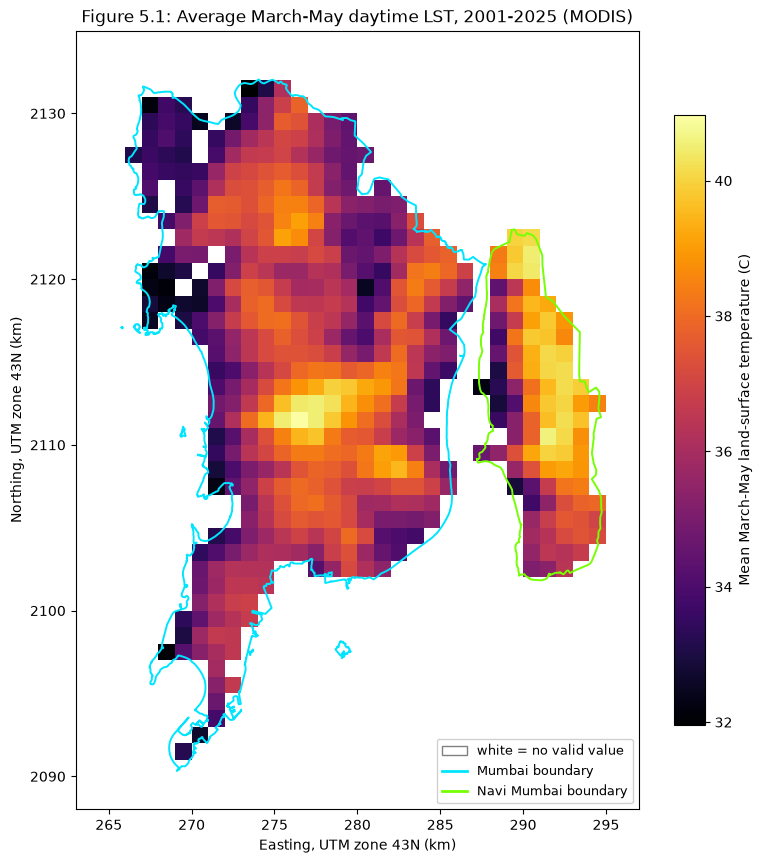

Mumbai       mean 36.05 C, min 31.96 C, max 40.96 C (449 cells)
Navi Mumbai  mean 37.58 C, min 32.30 C, max 40.59 C (99 cells)


In [2]:
fig, ax = P.raster_map(mam_mean, g1, geoms, cbar_label='Mean March-May land-surface temperature (C)',
                       title='Figure 5.1: Average March-May daytime LST, 2001-2025 (MODIS)')
P.save(fig, CHARTS / 'fig5_1_modis_mam_mean_2001_2025.png'); plt.show()
city_print(mam_mean, ids1)

## Figures 5.2a-c: March-May LST in 2005, 2015 and 2025 (MODIS)
**What they show:** the March-May mean LST for three years a decade apart, each in its own figure on the **same colour scale**, so colours are directly comparable between figures.

**How to read them:** a whole map being warmer in one year reflects that year's weather as well as urban change; Figures 5.6-5.7 separate the two.

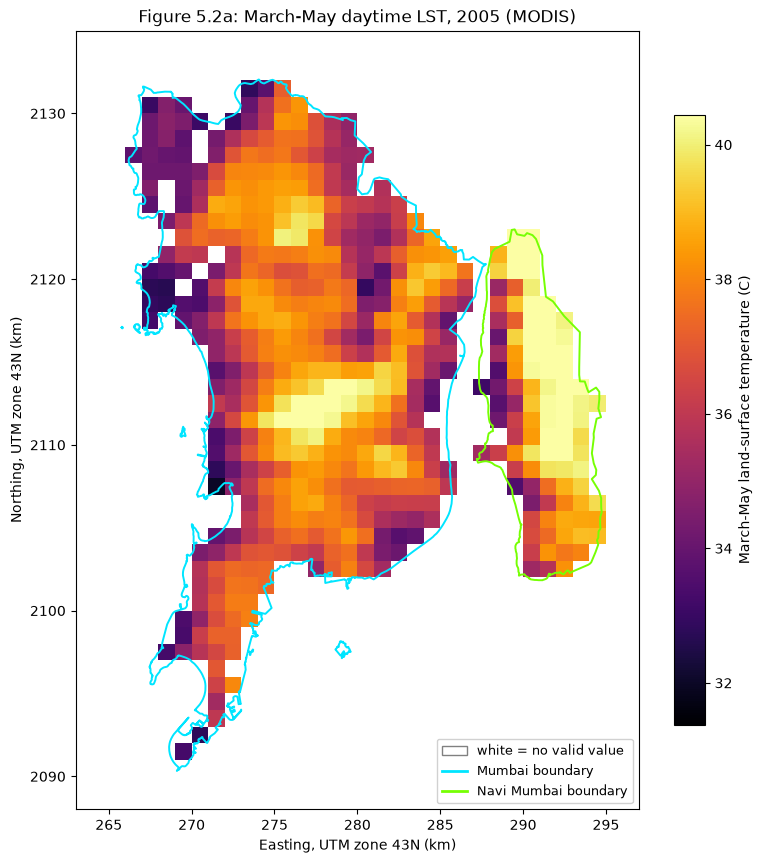

2005:
Mumbai       mean 36.74 C, min 32.01 C, max 41.10 C (449 cells)
Navi Mumbai  mean 38.53 C, min 33.15 C, max 42.06 C (99 cells)


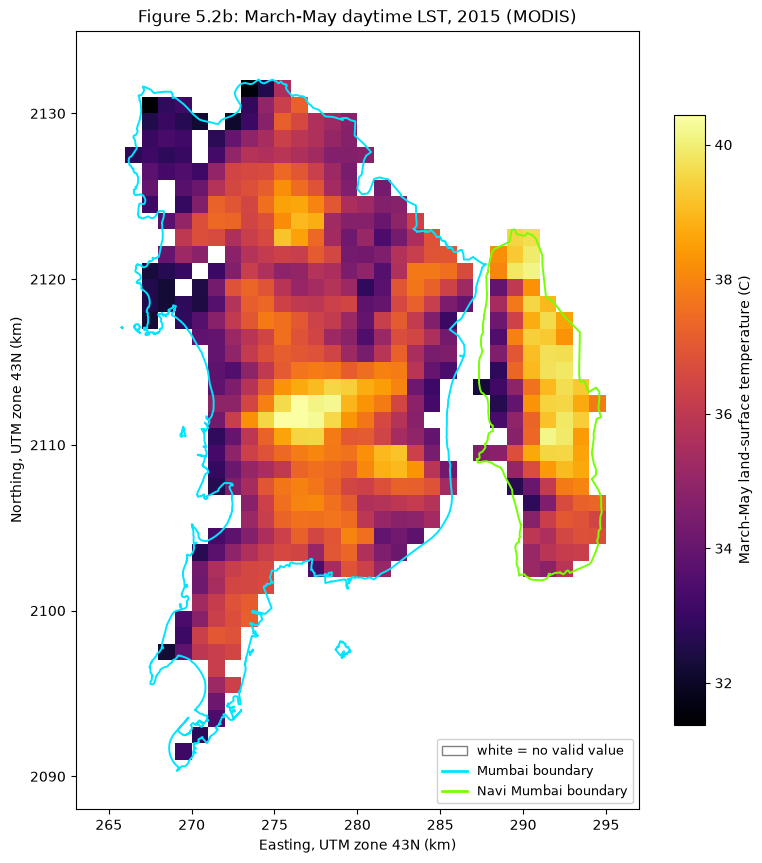

2015:
Mumbai       mean 35.78 C, min 31.39 C, max 41.00 C (449 cells)
Navi Mumbai  mean 37.17 C, min 32.32 C, max 40.18 C (99 cells)


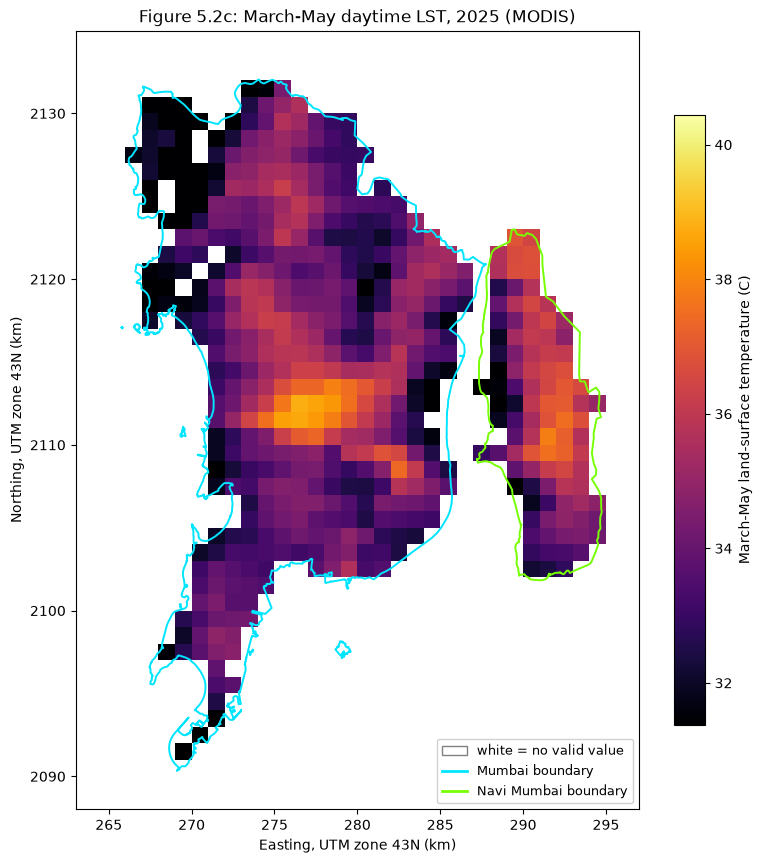

2025:
Mumbai       mean 33.86 C, min 29.60 C, max 38.79 C (449 cells)
Navi Mumbai  mean 34.87 C, min 30.84 C, max 37.85 C (99 cells)
shared colour scale: 31.4-40.4 C


In [3]:
sel = [2005, 2015, 2025]
maps_sel = {y: pp.read(MAPS / f'modis_lst_mam_{y}.tif')['lst_mam_mean_c'] for y in sel}
vmin = np.nanpercentile(np.stack(list(maps_sel.values())), 2); vmax = np.nanpercentile(np.stack(list(maps_sel.values())), 98)
for letter, y in zip('abc', sel):
    fig, ax = P.raster_map(maps_sel[y], g1, geoms, vmin=vmin, vmax=vmax, cbar_label='March-May land-surface temperature (C)',
                           title=f'Figure 5.2{letter}: March-May daytime LST, {y} (MODIS)')
    P.save(fig, CHARTS / f'fig5_2{letter}_modis_mam_{y}.png'); plt.show()
    print(f'{y}:'); city_print(maps_sel[y], ids1)
print(f'shared colour scale: {vmin:.1f}-{vmax:.1f} C')

## Figures 5.3: Detailed Landsat surface temperature, each selected year (30 m)
**What they show:** Landsat surface temperature, the March-May median of clear scenes, one figure per selected year on a shared colour scale. Detail here is ~100 m (thermal sensor), delivered on a 30 m grid.

**How to read them:** individual neighbourhoods, industrial areas, parks and water bodies are visible: the fine structure behind the 1 km MODIS pattern. Cells with few clear scenes are noisier.

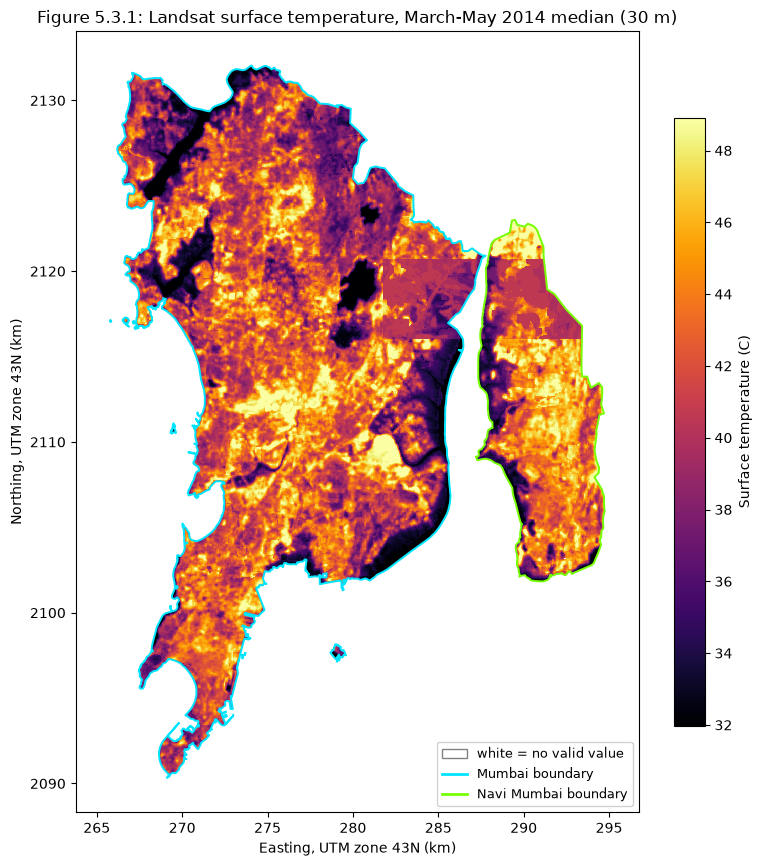

2014: median clear scenes per pixel 5
Mumbai       mean 41.0 C, min 29.2 C, max 55.6 C (528030 cells)
Navi Mumbai  mean 42.7 C, min 30.4 C, max 56.3 C (116669 cells)


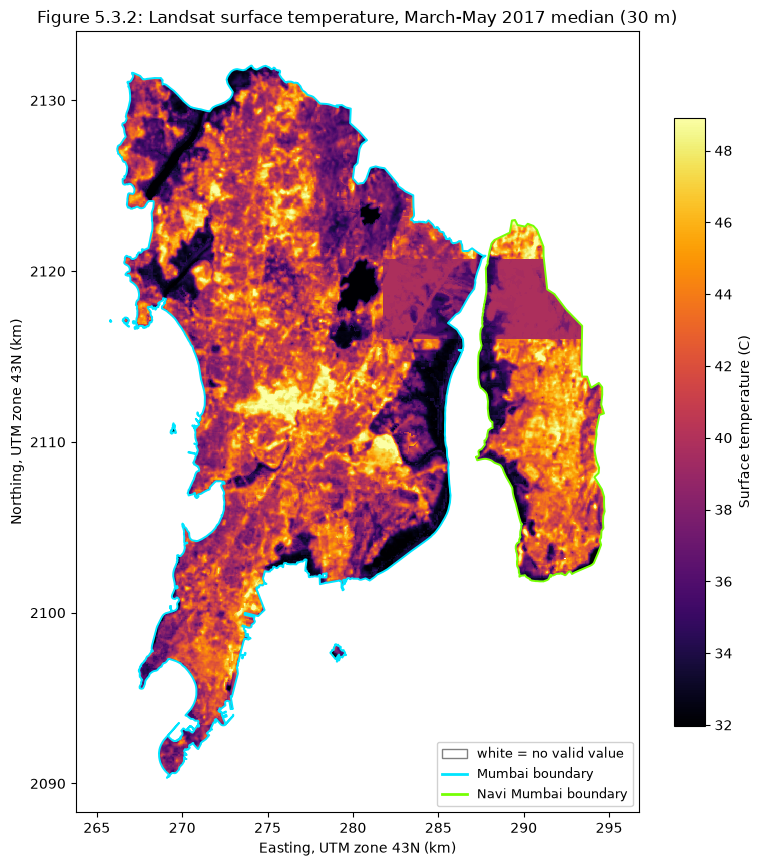

2017: median clear scenes per pixel 6
Mumbai       mean 40.0 C, min 29.4 C, max 53.5 C (528030 cells)
Navi Mumbai  mean 41.5 C, min 31.3 C, max 53.4 C (116669 cells)


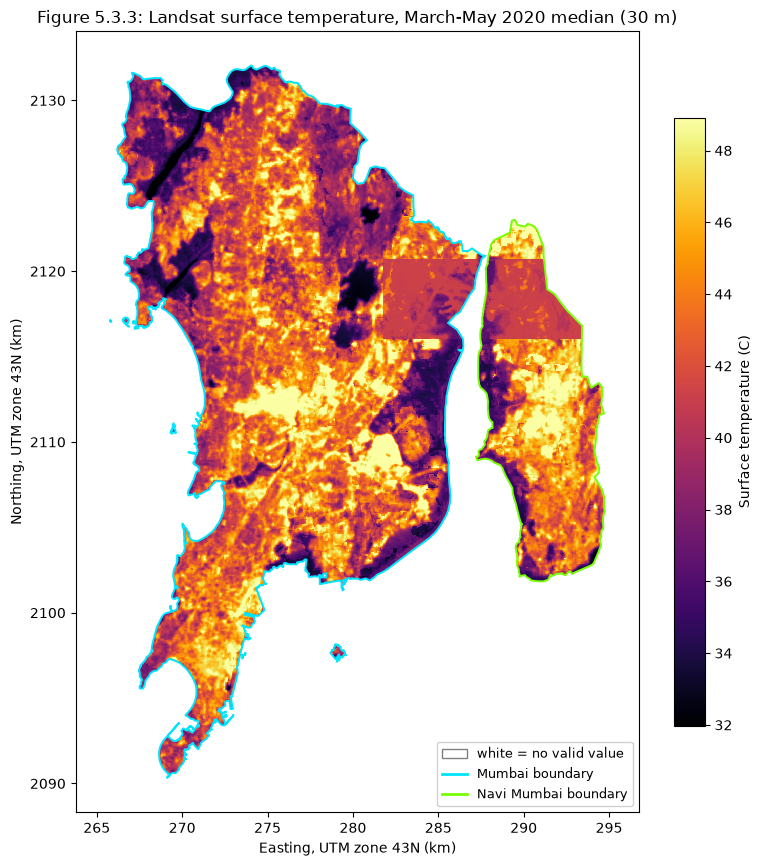

2020: median clear scenes per pixel 5
Mumbai       mean 41.9 C, min 27.7 C, max 56.9 C (528030 cells)
Navi Mumbai  mean 43.2 C, min 32.4 C, max 58.9 C (116669 cells)


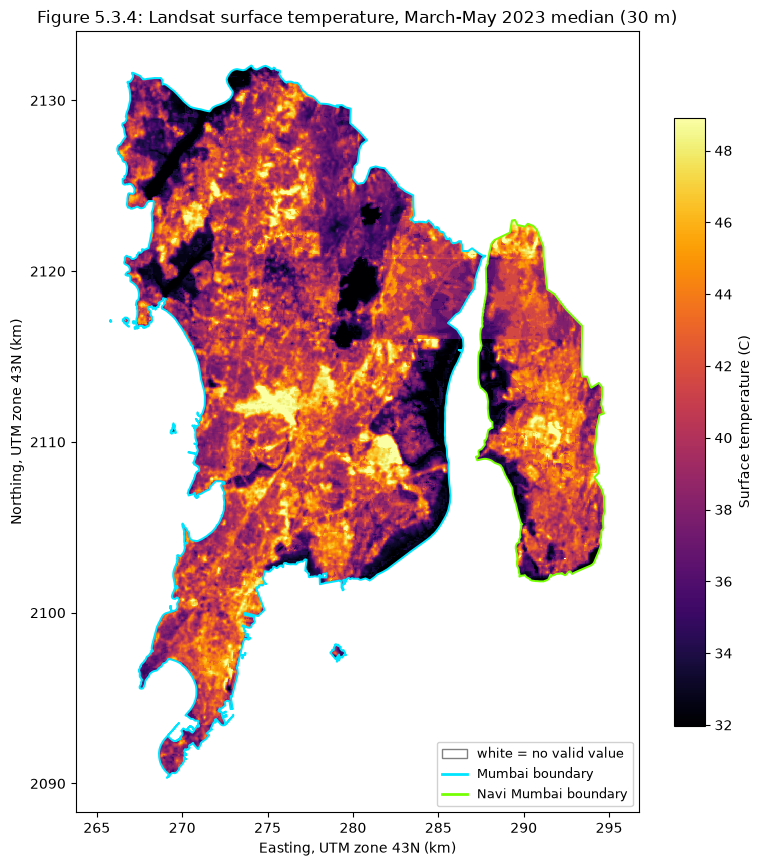

2023: median clear scenes per pixel 9
Mumbai       mean 39.9 C, min 29.0 C, max 53.3 C (528030 cells)
Navi Mumbai  mean 40.8 C, min 30.1 C, max 55.0 C (116669 cells)


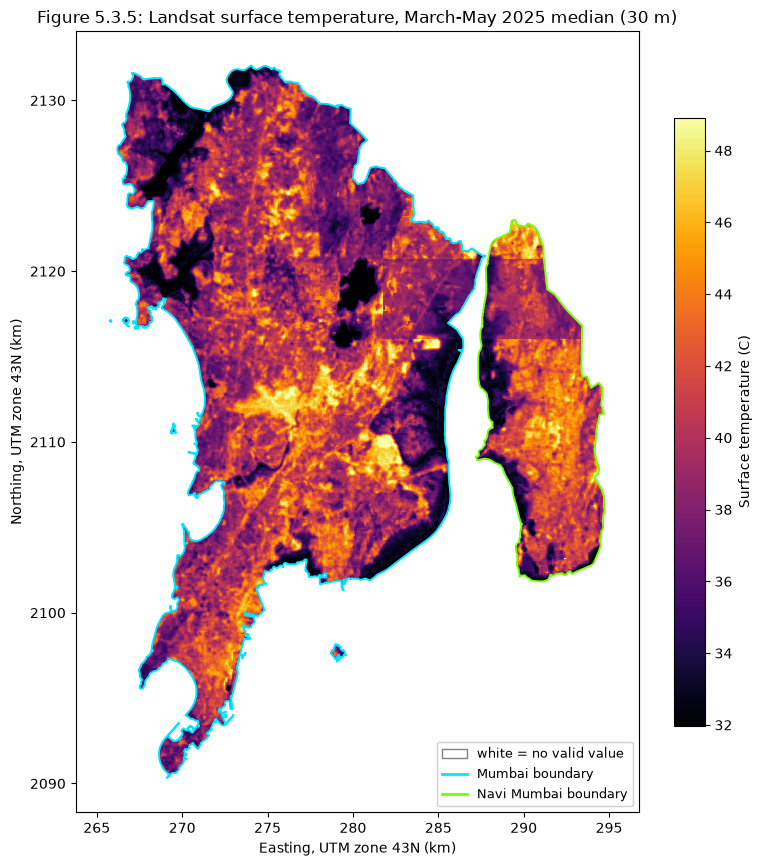

2025: median clear scenes per pixel 9
Mumbai       mean 39.2 C, min 28.7 C, max 52.9 C (528030 cells)
Navi Mumbai  mean 40.4 C, min 30.4 C, max 52.4 C (116669 cells)


In [4]:
years = [y for y in config.LANDSAT_YEARS if (MAPS / f'landsat_st_mam_{y}.tif').exists()]
ls_maps = {y: pp.read(MAPS / f'landsat_st_mam_{y}.tif') for y in years}
allv = np.concatenate([m['st_mam_median_c'][np.isfinite(m['st_mam_median_c'])] for m in ls_maps.values()])
lo, hi = np.percentile(allv, [2, 98])
for n, y in enumerate(years, start=1):
    m = ls_maps[y]
    fig, ax = P.raster_map(m['st_mam_median_c'], g30, geoms, vmin=lo, vmax=hi, cbar_label='Surface temperature (C)',
                           title=f'Figure 5.3.{n}: Landsat surface temperature, March-May {y} median (30 m)')
    P.save(fig, CHARTS / f'fig5_3_{n}_landsat_st_{y}.png'); plt.show()
    print(f'{y}: median clear scenes per pixel {int(np.median(m["clear_obs"][ids30 > 0]))}'); city_print(m['st_mam_median_c'], ids30, fmt='{:.1f}')

## Figure 5.4: Year-by-year city average LST (trend graph)
**What it shows:** each city's average March-May LST (solid lines with dots) and annual LST (dashed) for every year 2001-2025, with a straight-line trend for March-May. The legend gives the trend in degrees C per decade.

**How to read it:** year-to-year swings are weather (and how many clear composites a year had); the trend line shows the long-term direction. Annual means include the cloudy monsoon, where fewer composites are available.

**Caution, satellite drift:** NASA's Terra satellite (which carries this MODIS sensor) has been passing over earlier each year since 2022 (about 9:40 instead of 10:40 local solar time by 2025, see Figure 5.13). Earlier overpass = cooler ground, so 2022-2025 values and trends that include them are biased low by the satellite, not by the cities. City-relative results (Figures 5.5, 5.7) are not affected because the whole map shifts together.

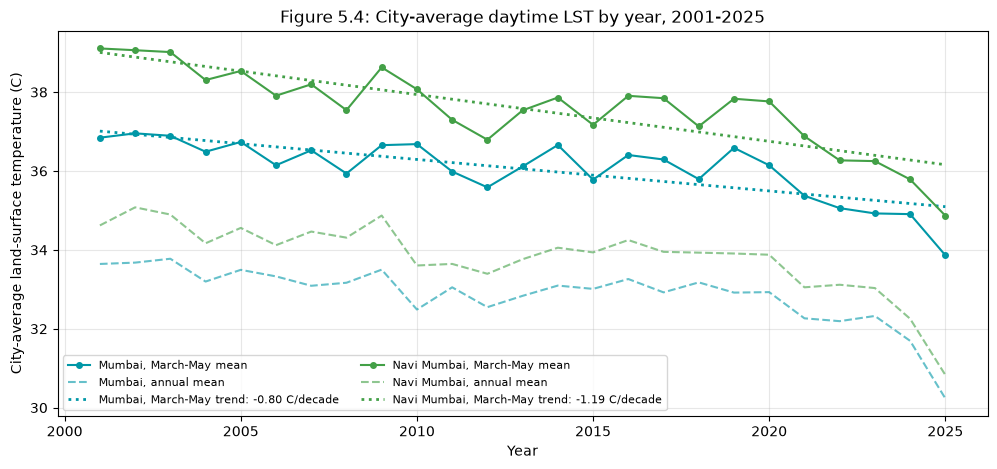

      season         city  years  mean_of_years_c  warmest_year_c  \
0  March-May       mumbai     25           36.053          36.954   
1  March-May  navi_mumbai     25           37.582          39.106   
2     annual       mumbai     25           32.873          33.775   
3     annual  navi_mumbai     25           33.827          35.078   

   coolest_year_c  
0          33.864  
1          34.867  
2          30.234  
3          30.829  


In [5]:
fig, ax = plt.subplots(figsize=(12, 5))
for k in pp.CITY_IDS:
    for season, ls_, lab in [('March-May', '-', 'March-May'), ('annual', '--', 'annual')]:
        d = stats[(stats.city == k) & (stats.season == season)].dropna(subset=['mean_c'])
        ax.plot(d.year, d.mean_c, ls_, marker='o' if season == 'March-May' else None, ms=4, color=COLOURS[k], alpha=1 if season == 'March-May' else 0.6,
                label=f'{config.CITIES[k]}, {lab} mean')
    d = stats[(stats.city == k) & (stats.season == 'March-May')].dropna(subset=['mean_c'])
    b, a = np.polyfit(d.year, d.mean_c, 1)
    ax.plot(d.year, a + b * d.year, ':', color=COLOURS[k], lw=2, label=f'{config.CITIES[k]}, March-May trend: {10 * b:+.2f} C/decade')
ax.set_xlabel('Year'); ax.set_ylabel('City-average land-surface temperature (C)')
ax.set_title('Figure 5.4: City-average daytime LST by year, 2001-2025'); ax.legend(fontsize=8, ncol=2); ax.grid(alpha=0.3)
P.save(fig, CHARTS / 'fig5_4_city_lst_by_year.png'); plt.show()
print(pd.read_csv(A / 'city_comparison.csv'))

## Figure 5.5: Persistent hotspots
**What it shows:** for each cell, the share of years (0-1) in which it was among the hottest 10% of its own city in March-May. Black outline = persistent hotspots (hot in at least half the years).

**How to read it:** cells near 1 are hot almost every year: stable hotspots, not one-off weather. Because the threshold is relative to each city, both cities always have hotspots by construction; compare their locations with land cover (Figures 3.6, 4.4).

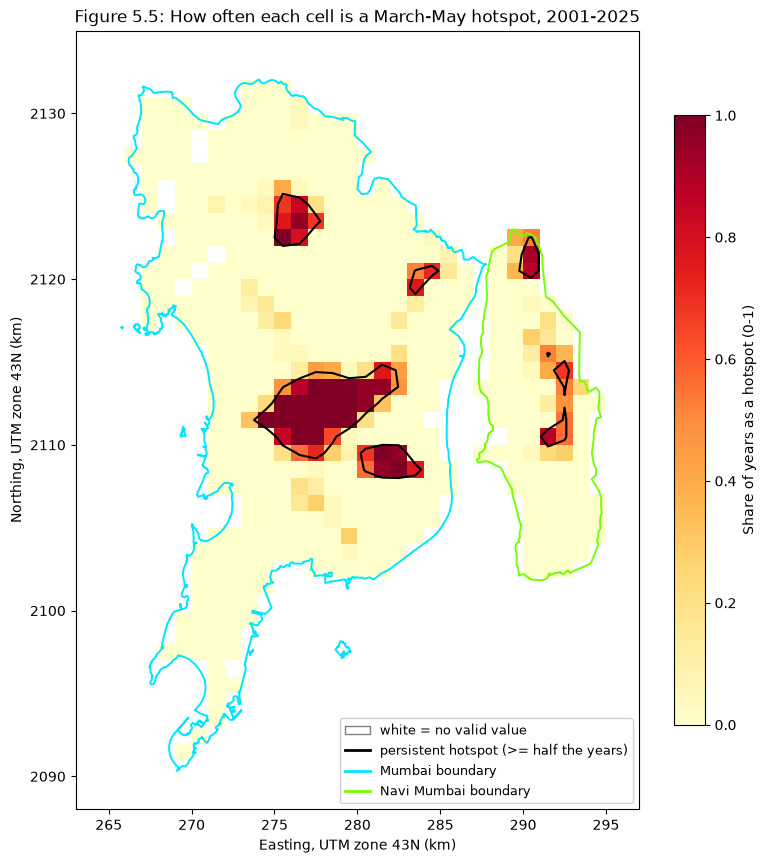

Mumbai: 42 persistent hotspot cells of 470 km2
Navi Mumbai: 9 persistent hotspot cells of 103 km2


In [6]:
from matplotlib.lines import Line2D
hs = pp.read(MAPS / 'hotspot_frequency.tif')
freq = hs['hotspot_share_of_years']
fig, ax = P.raster_map(freq, g1, geoms, cmap='YlOrRd', vmin=0, vmax=1, cbar_label='Share of years as a hotspot (0-1)',
                       title='Figure 5.5: How often each cell is a March-May hotspot, 2001-2025',
                       extra_handles=[Line2D([], [], color='black', lw=2, label='persistent hotspot (>= half the years)')])
ax.contour(np.where(np.isfinite(freq), freq, 0), levels=[an.PERSISTENT_SHARE], colors='black', linewidths=1.5,
           extent=P.extent_km(g1), origin='upper')
P.save(fig, CHARTS / 'fig5_5_hotspot_frequency.png'); plt.show()
for k, i in pp.CITY_IDS.items():
    print(f'{config.CITIES[k]}: {int(((ids1 == i) & (freq >= an.PERSISTENT_SHARE)).sum())} persistent hotspot cells of {int((ids1 == i).sum())} km2')

## Figure 5.6: Warming trend per cell
**What it shows:** the straight-line trend of each cell's March-May LST over 2001-2025, in degrees C per decade (red = warming, blue = cooling). Cells with fewer than 15 years of data are left white.

**How to read it:** +0.5 means about half a degree warmer every ten years. Trends from 25 noisy yearly values carry real uncertainty; small differences between neighbouring cells are not meaningful.

**Caution, satellite drift:** NASA's Terra satellite (which carries this MODIS sensor) has been passing over earlier each year since 2022 (about 9:40 instead of 10:40 local solar time by 2025, see Figure 5.13). Earlier overpass = cooler ground, so 2022-2025 values and trends that include them are biased low by the satellite, not by the cities. City-relative results (Figures 5.5, 5.7) are not affected because the whole map shifts together.

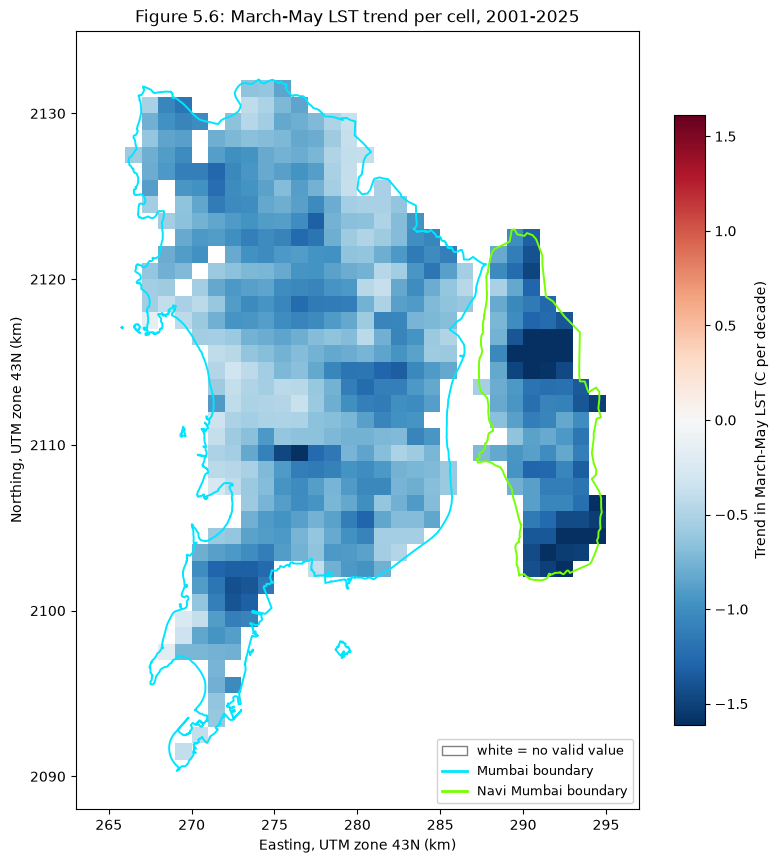

Mumbai       mean -0.80 C/decade, min -1.59 C/decade, max -0.15 C/decade (449 cells)
Navi Mumbai  mean -1.19 C/decade, min -1.86 C/decade, max -0.53 C/decade (99 cells)


In [7]:
tr = pp.read(MAPS / 'lst_trend_c_per_decade.tif')['trend_c_per_decade']
lim = np.nanpercentile(np.abs(tr), 98)
fig, ax = P.raster_map(tr, g1, geoms, cmap='RdBu_r', vmin=-lim, vmax=lim, cbar_label='Trend in March-May LST (C per decade)',
                       title='Figure 5.6: March-May LST trend per cell, 2001-2025')
P.save(fig, CHARTS / 'fig5_6_lst_trend.png'); plt.show()
city_print(tr, ids1, unit=' C/decade')

## Figure 5.7: Where heat moved, relative to the city
**What it shows:** each cell's temperature relative to its city average in 2021-2025, minus the same in 2001-2005. Overall warming of the whole city is removed.

**How to read it:** red cells became hotter *relative to the rest of the city* (often new construction); blue cells became relatively cooler. This isolates the change in the spatial distribution of heat (plan step 7).

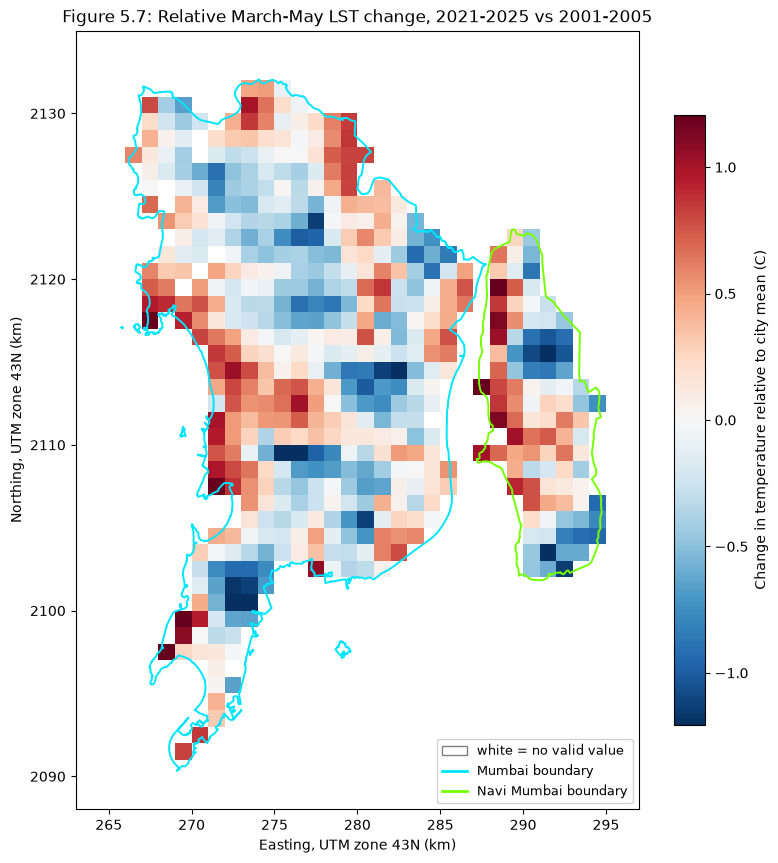

Mumbai       mean -0.00 C, min -1.72 C, max 1.47 C (449 cells)
Navi Mumbai  mean 0.00 C, min -1.26 C, max 1.38 C (99 cells)


In [8]:
rel = pp.read(MAPS / 'relative_lst_change.tif')['relative_change_c']
lim = np.nanpercentile(np.abs(rel), 98)
fig, ax = P.raster_map(rel, g1, geoms, cmap='RdBu_r', vmin=-lim, vmax=lim,
                       cbar_label='Change in temperature relative to city mean (C)',
                       title='Figure 5.7: Relative March-May LST change, 2021-2025 vs 2001-2005')
P.save(fig, CHARTS / 'fig5_7_relative_change.png'); plt.show()
city_print(rel, ids1)

## Figure 5.8: LST versus built-up share (MODIS, 1 km)
**What it shows:** the long-term March-May LST (Figure 5.1) of 1 km cells grouped by how built-up they are (from WorldCover). Boxes show the middle 50% of cells, the line the median, whiskers the typical range; the numbers above give how many cells are in each group.

**How to read it:** if built-up land drives heat, boxes rise from left to right.

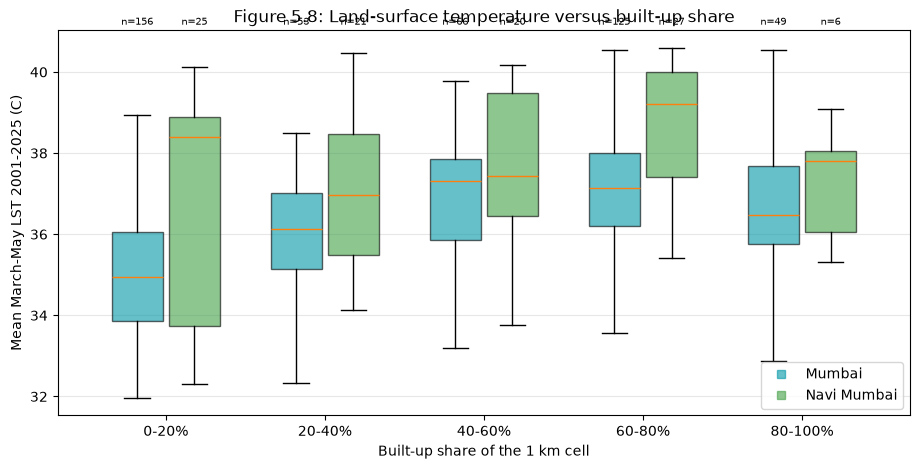

          city built_up_share  cells  mean_lst_c  median_lst_c
0       mumbai          0-20%    156      34.962        34.938
1       mumbai         20-40%     53      35.891        36.121
2       mumbai         40-60%     66      36.789        37.317
3       mumbai         60-80%    125      36.859        37.149
4       mumbai        80-100%     49      36.651        36.467
5  navi_mumbai          0-20%     25      36.778        38.392
6  navi_mumbai         20-40%     21      37.075        36.973
7  navi_mumbai         40-60%     20      37.688        37.432
8  navi_mumbai         60-80%     27      38.710        39.204
9  navi_mumbai        80-100%      6      37.274        37.815


In [9]:
share = pp.read(config.FEATURES / 'static_1km.tif')['share_built_up']
edges = [0, 0.2, 0.4, 0.6, 0.8, 1.0001]; labels = ['0-20%', '20-40%', '40-60%', '60-80%', '80-100%']
fig, ax = plt.subplots(figsize=(11, 5))
for off, (k, i) in zip((-0.18, 0.18), pp.CITY_IDS.items()):
    data = [mam_mean[(ids1 == i) & (share >= lo) & (share < hi) & np.isfinite(mam_mean)] for lo, hi in zip(edges[:-1], edges[1:])]
    pos = np.arange(5) + off
    bp = ax.boxplot([d if d.size else [np.nan] for d in data], positions=pos, widths=0.32, patch_artist=True, showfliers=False)
    for p_ in bp['boxes']:
        p_.set_facecolor(COLOURS[k]); p_.set_alpha(0.6)
    for x, d in zip(pos, data):
        ax.text(x, np.nanmax(mam_mean) + 0.2, f'n={d.size}', ha='center', fontsize=7)
    ax.plot([], [], 's', color=COLOURS[k], alpha=0.6, label=config.CITIES[k])
ax.set_xticks(range(5), labels); ax.set_xlabel('Built-up share of the 1 km cell')
ax.set_ylabel('Mean March-May LST 2001-2025 (C)'); ax.legend()
ax.set_title('Figure 5.8: Land-surface temperature versus built-up share'); ax.grid(axis='y', alpha=0.3)
P.save(fig, CHARTS / 'fig5_8_lst_vs_builtup.png'); plt.show()
print(pd.read_csv(A / 'lst_by_builtup_share.csv'))

## Figures 5.9 and 5.10: Landsat surface temperature versus NDVI and NDBI (30 m)
**What they show:** every land pixel of both cities for the most recent selected year, as a density plot (darker = more pixels): surface temperature against NDVI (vegetation), then against NDBI (built-up). The legend gives the correlation coefficient r per city (-1 to +1).

**How to read them:** a negative r with NDVI means greener pixels are cooler; a positive r with NDBI means more built-up pixels are hotter. |r| above about 0.5 is a strong relationship.

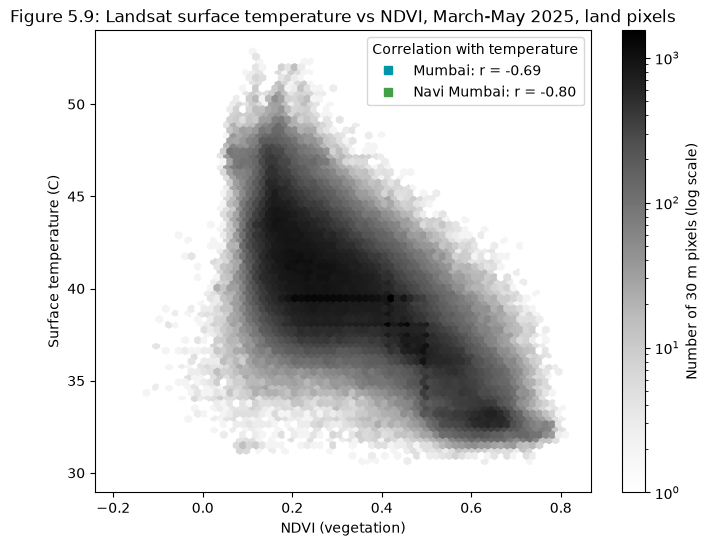

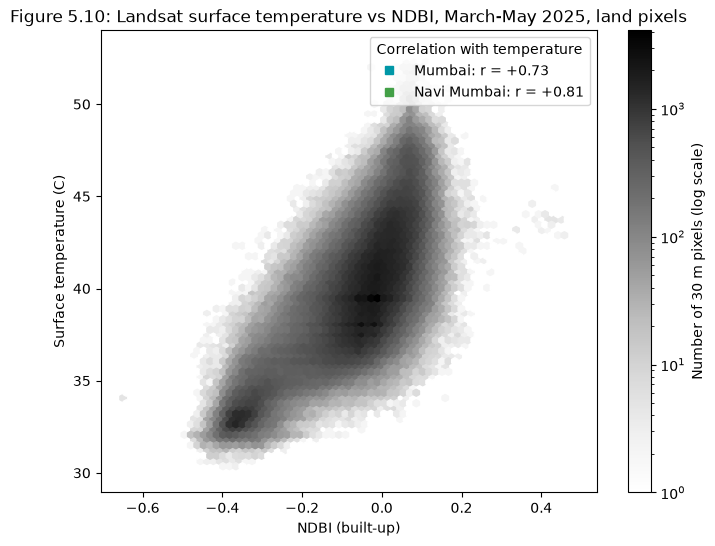

   year         city  land_pixels  r_st_ndvi  r_st_ndbi  r_st_ndwi
0  2014       mumbai       496889     -0.678      0.715      0.625
1  2014  navi_mumbai       112994     -0.735      0.771      0.694
2  2017       mumbai       496889     -0.703      0.744      0.641
3  2017  navi_mumbai       112994     -0.766      0.761      0.752
4  2020       mumbai       496889     -0.687      0.694      0.633
5  2020  navi_mumbai       112994     -0.748      0.688      0.706
6  2023       mumbai       496889     -0.689      0.739      0.632
7  2023  navi_mumbai       112994     -0.759      0.798      0.709
8  2025       mumbai       496889     -0.689      0.728      0.624
9  2025  navi_mumbai       112994     -0.795      0.810      0.742


In [10]:
Y = max(years)
f = pp.read(config.FEATURES / f'landsat_{Y}_30m.tif')
groups = pp.read(config.FEATURES / 'static_30m.tif')['landcover_group'].astype(int)
land = (ids30 > 0) & (groups != ft.GROUP_CODES['water']) & np.isfinite(f['st_celsius'])
corr = pd.read_csv(A / 'landsat_lst_vs_indices.csv')
for num, idx, xlab in [(9, 'ndvi', 'NDVI (vegetation)'), (10, 'ndbi', 'NDBI (built-up)')]:
    ok = land & np.isfinite(f[idx])
    fig, ax = plt.subplots(figsize=(8, 6))
    hb = ax.hexbin(f[idx][ok], f['st_celsius'][ok], gridsize=70, bins='log', cmap='Greys', mincnt=1)
    fig.colorbar(hb, ax=ax, label='Number of 30 m pixels (log scale)')
    handles = []
    for k in pp.CITY_IDS:
        r = corr[(corr.year == Y) & (corr.city == k)][f'r_st_{idx}'].iloc[0]
        handles.append(Line2D([], [], ls='', marker='s', color=COLOURS[k], label=f'{config.CITIES[k]}: r = {r:+.2f}'))
    ax.legend(handles=handles, title='Correlation with temperature', loc='upper right')
    ax.set_xlabel(xlab); ax.set_ylabel('Surface temperature (C)')
    ax.set_title(f'Figure 5.{num}: Landsat surface temperature vs {idx.upper()}, March-May {Y}, land pixels')
    P.save(fig, CHARTS / f'fig5_{num}_st_vs_{idx}.png'); plt.show()
print(corr[['year', 'city', 'land_pixels', 'r_st_ndvi', 'r_st_ndbi', 'r_st_ndwi']])

## Figure 5.11: Average surface temperature by land-cover group (Landsat)
**What it shows:** the mean Landsat March-May surface temperature of each land-cover group (built-up, vegetation, water, other), per city, for every selected year.

**How to read it:** the gap between the built-up and vegetation bars is the local urban heat effect in degrees C.

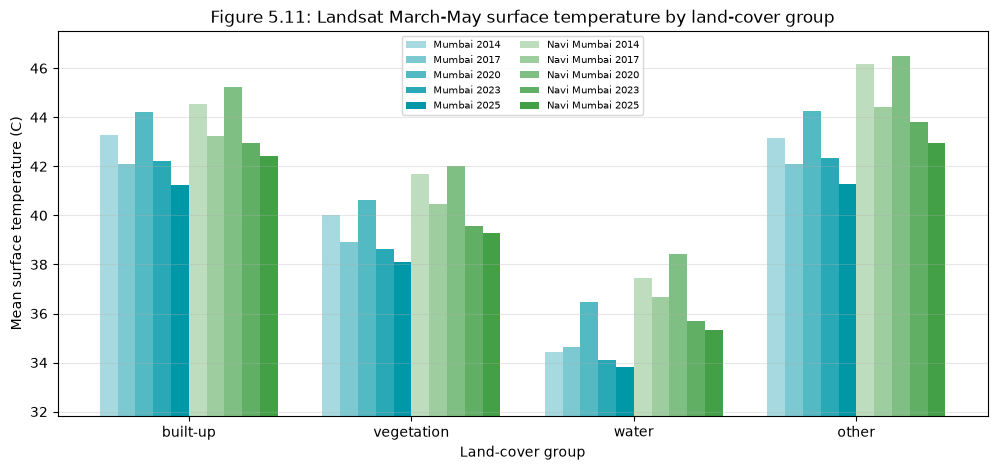

built-up minus vegetation (C):
city  mumbai  navi_mumbai
year                     
2014    3.28         2.86
2017    3.18         2.77
2020    3.57         3.22
2023    3.62         3.38
2025    3.13         3.13


In [11]:
grp_cols = [c for c in corr.columns if c.startswith('mean_st_')]
names = [c.replace('mean_st_', '').replace('_c', '').replace('_', '-') for c in grp_cols]
fig, ax = plt.subplots(figsize=(12, 5))
w = 0.08
for j, (k, y) in enumerate([(k, y) for k in pp.CITY_IDS for y in years]):
    row = corr[(corr.city == k) & (corr.year == y)][grp_cols].iloc[0].astype(float)
    shade = 0.35 + 0.65 * years.index(y) / max(len(years) - 1, 1)
    ax.bar(np.arange(len(grp_cols)) + (j - len(years) + 0.5) * w, row.values, width=w, color=COLOURS[k], alpha=shade,
           label=f'{config.CITIES[k]} {y}')
ax.set_xticks(range(len(grp_cols)), names); ax.set_xlabel('Land-cover group'); ax.set_ylabel('Mean surface temperature (C)')
ax.set_ylim(np.nanmin(corr[grp_cols].astype(float).values) - 2, np.nanmax(corr[grp_cols].astype(float).values) + 1)
ax.set_title('Figure 5.11: Landsat March-May surface temperature by land-cover group'); ax.legend(ncol=2, fontsize=7); ax.grid(axis='y', alpha=0.3)
P.save(fig, CHARTS / 'fig5_11_st_by_landcover.png'); plt.show()
gap = corr.assign(gap=corr.mean_st_built_up_c.astype(float) - corr.mean_st_vegetation_c.astype(float))
print('built-up minus vegetation (C):'); print(gap.pivot_table(index='year', columns='city', values='gap').round(2))

## Figure 5.12: Mumbai versus Navi Mumbai, distribution of cell temperatures
**What it shows:** histograms of the long-term March-May LST (Figure 5.1) of every 1 km cell, one per city (overlapping, semi-transparent). Dashed lines mark each city's median.

**How to read it:** a city whose histogram sits further right is hotter overall; a wider histogram means more contrast between its hot and cool areas.

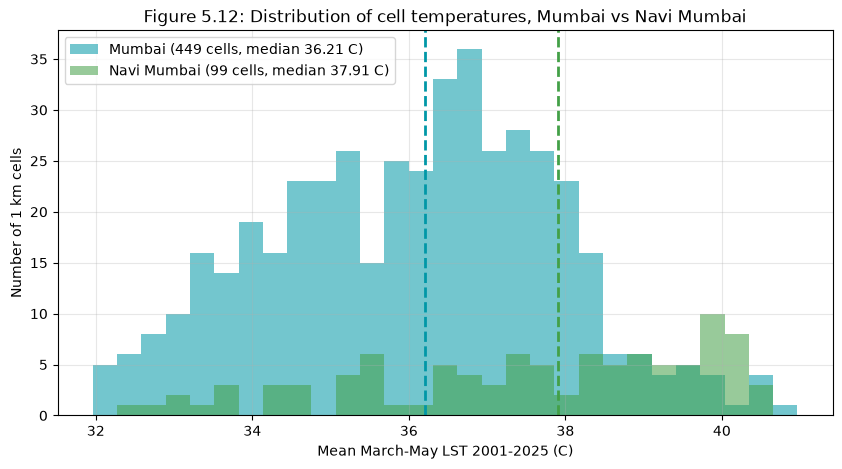

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))
bins = np.linspace(np.nanmin(mam_mean), np.nanmax(mam_mean), 30)
for k, i in pp.CITY_IDS.items():
    v = mam_mean[(ids1 == i) & np.isfinite(mam_mean)]
    ax.hist(v, bins=bins, color=COLOURS[k], alpha=0.55, label=f'{config.CITIES[k]} ({v.size} cells, median {np.median(v):.2f} C)')
    ax.axvline(np.median(v), color=COLOURS[k], ls='--', lw=2)
ax.set_xlabel('Mean March-May LST 2001-2025 (C)'); ax.set_ylabel('Number of 1 km cells')
ax.set_title('Figure 5.12: Distribution of cell temperatures, Mumbai vs Navi Mumbai'); ax.legend(); ax.grid(alpha=0.3)
P.save(fig, CHARTS / 'fig5_12_city_distribution.png'); plt.show()

## Figure 5.13: Check for satellite overpass drift
**What it shows:** bars = the average time of day (local solar time) at which MODIS Terra observed the study area in March-May of each year (from the product's own Day_view_time band); line = city-average March-May LST (right axis).

**How to read it:** the overpass was stable at about 10:40 until 2021, then moved about an hour earlier by 2025, and LST falls with it. Trends that include 2022-2025 therefore mix urban change with this satellite effect. Over the stable years 2002-2021 a smaller cooling remains, which this analysis does not explain; it should be treated as unconfirmed. This matters for Phase 7, whose test years (2023-2025) fall in the drift period.

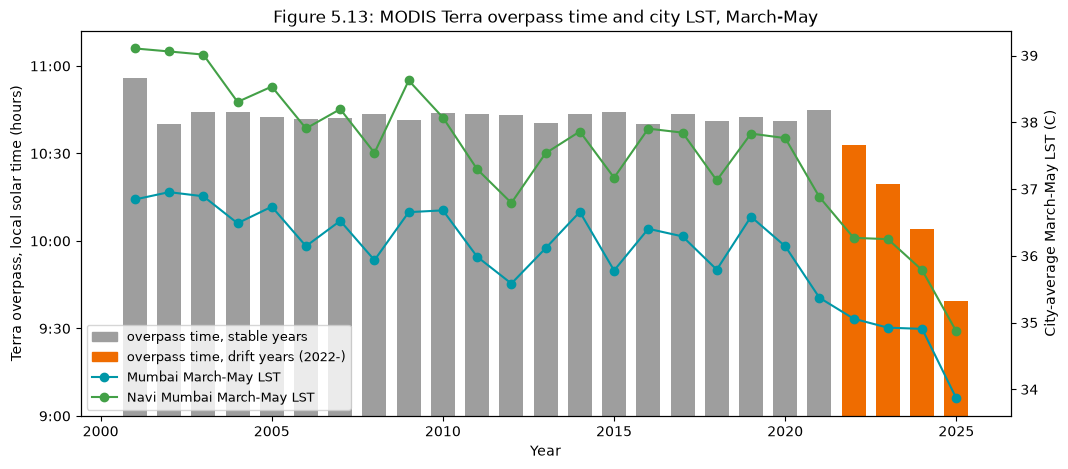

2001-2025                    Mumbai       trend -0.80 C/decade
2001-2025                    Navi Mumbai  trend -1.19 C/decade
2002-2021 (stable overpass)  Mumbai       trend -0.42 C/decade
2002-2021 (stable overpass)  Navi Mumbai  trend -0.75 C/decade


In [13]:
from urban_heat import acquisition as acq
ov = pd.read_csv(acq.overpass_path())
fig, ax = plt.subplots(figsize=(12, 5))
hrs = ov.mean_day_view_time_local_solar_hours
bars = ax.bar(ov.year, hrs, color=['#9e9e9e' if y < 2022 else '#ef6c00' for y in ov.year], width=0.7)
ax.set_ylim(9.0, 11.2); ax.set_ylabel('Terra overpass, local solar time (hours)')
ax.set_yticks([9, 9.5, 10, 10.5, 11], ['9:00', '9:30', '10:00', '10:30', '11:00'])
ax2 = ax.twinx()
for k in pp.CITY_IDS:
    d = stats[(stats.city == k) & (stats.season == 'March-May')]
    ax2.plot(d.year, d.mean_c, 'o-', color=COLOURS[k], label=f'{config.CITIES[k]} March-May LST')
ax2.set_ylabel('City-average March-May LST (C)')
from matplotlib.patches import Patch
handles = [Patch(color='#9e9e9e', label='overpass time, stable years'), Patch(color='#ef6c00', label='overpass time, drift years (2022-)')]
handles += ax2.get_legend_handles_labels()[0]
ax.legend(handles=handles, loc='lower left', fontsize=9)
ax.set_xlabel('Year'); ax.set_title('Figure 5.13: MODIS Terra overpass time and city LST, March-May')
P.save(fig, CHARTS / 'fig5_13_terra_overpass_drift.png'); plt.show()
for label, yrs in [('2001-2025', range(2001, 2026)), ('2002-2021 (stable overpass)', range(2002, 2022))]:
    for k in pp.CITY_IDS:
        d = stats[(stats.city == k) & (stats.season == 'March-May') & stats.year.isin(list(yrs))]
        print(f'{label:28s} {config.CITIES[k]:12s} trend {10 * np.polyfit(d.year, d.mean_c, 1)[0]:+.2f} C/decade')